<a href="https://colab.research.google.com/github/CoralsINPA/RedSeaCoralIdentifier/blob/claude%2Ffervent-cerf-h6mv5z/%D7%A2%D7%95%D7%AA%D7%A7_%D7%A9%D7%9C_WeakClassification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# WeakClassification Notebook

Classifies segmented coral crops into **20 Red Sea genera** using zero-shot CLIP-family models. The pipeline:
1. Loads SAM-generated masks from the CoralMasking notebook
2. Applies quality filters (area, aspect ratio, containment, sharpness)
3. Encodes each crop with BioCLIP / BioCLIP-2 / SigLIP-2
4. Matches against genus text embeddings (taxonomy, descriptive, or ensemble prompts)
5. Evaluates against expert labels and visualizes results

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


## Install Dependencies

Installs `open_clip_torch` (for BioCLIP/BioCLIP-2 inference) alongside PyTorch, torchvision, pycocotools, and transformers.

In [ ]:
pip install open_clip_torch torch torchvision pycocotools transformers

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 29.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.8/44.8 kB 4.6 MB/s eta 0:00:00


## Setup: Paths & Run Configuration

Configures the base paths on Google Drive, sets the segmentation parameter run name (`iou60_sta55_pts32`), and creates output directories for JSON annotations and visualizations.

In [ ]:
# ======================================
# CELL: Weak Labeling with BioCLIP-FT (ReefNet)
# ======================================
import os
import torch
import cv2
import json
import numpy as np
import pandas as pd
from tqdm import tqdm
from PIL import Image
import open_clip

# pip install open_clip_torch  (if not already installed)

# ⚡ MEMORY OPTIMIZATION: Use 12x12 grid = 144 points
POINTS_PER_SIDE = 32
IOU_THRESH = 0.60
STABILITY_THRESH = 0.55
MIN_MASK_REGION_AREA = 100

# ⚙️ PATH SETUP
RUN_NAME = f"iou{int(IOU_THRESH*100)}_sta{int(STABILITY_THRESH*100)}_pts{int(POINTS_PER_SIDE)}"
print(f"📁 Run name: {RUN_NAME}")
base_path = '/content/drive/MyDrive/colab notebooks/CoralsMasking'
data_path = os.path.join(base_path, 'data_all')
repo_path = os.path.join(base_path, 'CoralSCOP')
checkpoints_path = os.path.join(repo_path, 'checkpoints')
# results_dir = os.path.join(base_path, 'results')

# Create output directories
results_root = os.path.join(base_path, 'results_all')
run_dir = os.path.join(results_root, RUN_NAME)
json_dir = os.path.join(run_dir, 'json')
vis_dir = os.path.join(run_dir, 'visualizations')
os.makedirs(json_dir, exist_ok=True)
os.makedirs(vis_dir, exist_ok=True)

📁 Run name: iou60_sta55_pts32


## Quality Filters & Shared Utilities

Defines the mask quality filters applied before classification:
- **MIN_AREA** (25,000 px²) — removes tiny fragments
- **MAX_ASPECT_RATIO** (3.0) — removes elongated slivers
- **CONTAINMENT_THRESH** (0.80) — when a small mask is ≥80% inside a larger one, drop the larger (keeps the finer-grained segment)

Also sets the model and prompt configuration (`MODEL_VERSION`, `PROMPT_FORMAT`, `USE_MASK`).

In [ ]:
# ======================================
# CELL: Shared filter parameters & functions
# (must run before counts cache AND before labeling)
# ======================================
import pycocotools.mask as mask_util
import numpy as np
import cv2
import os

# ======================================
# CONTROLS
# ======================================
SAMPLE_ONLY        = True
SAMPLE_SIZE        = 50
RESUME             = False

MIN_AREA           = 25000
CONTAINMENT_THRESH = 0.80
MAX_ASPECT_RATIO   = 3.0
SHARPNESS_THRESHOLD = 80

# "finetuned-bioclip"  — ReefNet fine-tune of BioCLIP v1 (ViT-B/16, coral-specific)
# "bioclip2"           — BioCLIP v2, trained on 200M biology images (ViT-H/14, stronger general bio)
# "siglip2"            — Google SigLIP 2 SO400M (0.9B, sigmoid loss, better calibrated, 384px)
#                        Use PROMPT_FORMAT="descriptive" — taxonomy strings not useful here
MODEL_VERSION      = "finetuned-bioclip"

# "taxonomy"   — full Linnaean string (best for BioCLIP, matches training format)
# "descriptive"— morphological natural language descriptions
# "ensemble"   — averages taxonomy + descriptive + common-name embeddings (recommended)
# hybrid
PROMPT_FORMAT      = "taxonomy"

SAMPLE_MODE        = "best"
RANDOM_SEED        = 42

USE_MASK           = True
MASK_BACKGROUND    = "black"
MASK_PADDING_PCT   = 0.05
# ======================================

def decode_rle(rle):
    if isinstance(rle['counts'], str):
        rle = {'size': rle['size'], 'counts': rle['counts'].encode('utf-8')}
    return mask_util.decode(rle).astype(bool)

def bbox_intersection(b1, b2):
    x1, y1, w1, h1 = b1
    x2, y2, w2, h2 = b2
    ix = max(0, min(x1+w1, x2+w2) - max(x1, x2))
    iy = max(0, min(y1+h1, y2+h2) - max(y1, y2))
    return ix * iy

def aspect_ratio(bbox):
    _, _, w, h = bbox
    return max(w, h) / max(min(w, h), 1)

def filter_annotations(annotations, min_area, containment_thresh, max_aspect_ratio):
    candidates = [a for a in annotations if a['area'] >= min_area]
    candidates = [a for a in candidates if aspect_ratio(a['bbox']) <= max_aspect_ratio]
    if len(candidates) <= 1:
        return candidates
    to_remove = set()
    for i in range(len(candidates)):
        for j in range(len(candidates)):
            if i == j or candidates[j]['id'] in to_remove:
                continue
            a_small, a_large = candidates[i], candidates[j]
            if a_large['area'] <= a_small['area']:
                continue
            if bbox_intersection(a_small['bbox'], a_large['bbox']) == 0:
                continue
            mask_small = decode_rle(a_small['segmentation'])
            mask_large = decode_rle(a_large['segmentation'])
            containment = np.logical_and(mask_small, mask_large).sum() / a_small['area']
            if containment >= containment_thresh:
                to_remove.add(a_large['id'])
    return [a for a in candidates if a['id'] not in to_remove]


json_files_all = sorted([f for f in os.listdir(json_dir) if f.endswith('.json')])
print(f"✅ Filter functions ready | {len(json_files_all)} JSON files found")

✅ Filter functions ready | 1714 JSON files found


## Expert Evaluation Function

Defines `evaluate_against_expert()` — a reusable function that takes any model's prediction DataFrame and scores it against Assaf's hand-labeled test set of 78 crops. Reports overall accuracy, per-genus recall and precision, and the top confusion pairs. The join key is `(image_name, coral_id)`, so it works across different model runs.

In [ ]:
# # ======================================
# # CELL: Evaluate any model against Assaf's expert test set
# # ======================================
# # STEP 1 (one-time): Run build_expert_test_set.py in the WeakClassification
# #         notebook to produce assaf_expert_test_set.csv with real coral IDs.
# #         Then copy it to a fixed location on Drive:
# #
# #   import shutil
# #   shutil.copy(
# #       os.path.join(run_dir, 'assaf_expert_test_set.csv'),
# #       '/content/drive/MyDrive/colab notebooks/CoralsMasking/assaf_expert_test_set.csv'
# #   )
# #
# # STEP 2 (every notebook): Paste this cell. It loads the test set by
# #         image_name + coral_id — works regardless of which model or
# #         pipeline produced the predictions.
# # ======================================

# import pandas as pd
# import os

# # ── CONFIG — adjust paths to your setup ─────────────────────────────────────
# EXPERT_CSV = '/content/drive/MyDrive/colab notebooks/CoralsMasking/assaf_expert_test_set.csv'

# # Your model's predictions — must have: image_name, coral_id, predicted_genus
# # (and optionally 'confidence')
# # PREDICTIONS_CSV = os.path.join(run_dir, f'coral_weak_labels_{MODEL_VERSION}_{PROMPT_FORMAT}_{crop_mode}.csv')
# # df_pred = pd.read_csv(PREDICTIONS_CSV)

# # ── EVAL FUNCTION ───────────────────────────────────────────────────────────
# def evaluate_against_expert(predictions_df, expert_csv=EXPERT_CSV, include_unidentifiable=False):
#     """
#     Evaluate any model's predictions against Assaf's expert test set.
#     Joins on (image_name, coral_id) so it works across notebooks.

#     Parameters
#     ----------
#     predictions_df : DataFrame
#         Must have columns: image_name, coral_id, predicted_genus
#     expert_csv : str
#         Path to assaf_expert_test_set.csv (with real coral IDs baked in)
#     include_unidentifiable : bool
#         If True, include unidentifiable crops in the report (as automatic misses).
#         Default False = accuracy only on crops Assaf could identify.

#     Returns
#     -------
#     dict with accuracy, per-genus accuracy, confusion pairs, full details df
#     """
#     expert = pd.read_csv(expert_csv)
#     print(f"📋 Expert test set: {len(expert)} crops total")
#     print(f"   Identifiable: {(expert['is_correct'] != 'unidentifiable').sum()}")
#     print(f"   Unidentifiable: {(expert['is_correct'] == 'unidentifiable').sum()}")

#     if not include_unidentifiable:
#         expert = expert[expert['is_correct'] != 'unidentifiable'].copy()

#     # Join predictions to expert labels on the unique coral key
#     merged = predictions_df[['image_name', 'coral_id', 'predicted_genus']].merge(
#         expert[['image_name', 'coral_id', 'expert_genus', 'is_correct']],
#         on=['image_name', 'coral_id'],
#         how='inner',
#         suffixes=('_model', '_expert')
#     )

#     if len(merged) == 0:
#         print("\n⚠️  No matching crops found!")
#         print("    Check that image_name and coral_id columns match between your")
#         print("    predictions and the expert CSV. Common issues:")
#         print("    - Different image resolution → different coral_id numbering")
#         print("    - Filename mismatch (extensions, case)")
#         # Show a sample from each for debugging
#         print(f"\n    Your predictions sample:")
#         print(predictions_df[['image_name', 'coral_id']].head(3).to_string(index=False))
#         print(f"\n    Expert CSV sample:")
#         print(expert[['image_name', 'coral_id']].head(3).to_string(index=False))
#         return None

#     n_expert = len(expert)
#     n_matched = len(merged)
#     if n_matched < n_expert:
#         print(f"\n⚠️  Matched {n_matched}/{n_expert} expert crops — "
#               f"{n_expert - n_matched} crops not found in your predictions")

#     # Score
#     merged['match'] = merged['predicted_genus'] == merged['expert_genus']
#     accuracy = merged['match'].mean()

#     # Per-genus recall (how well does the model find each true genus)
#     per_genus = (merged.groupby('expert_genus')['match']
#                  .agg(['mean', 'sum', 'count'])
#                  .rename(columns={'mean': 'recall', 'sum': 'correct', 'count': 'total'})
#                  .sort_values('recall'))

#     # Per-genus precision (of everything predicted as X, how many are right)
#     precision_data = []
#     for genus in sorted(merged['predicted_genus'].unique()):
#         pred_as = merged[merged['predicted_genus'] == genus]
#         prec = pred_as['match'].mean()
#         precision_data.append({
#             'predicted_genus': genus,
#             'precision': prec,
#             'correct': pred_as['match'].sum(),
#             'total_predicted': len(pred_as)
#         })
#     per_genus_precision = pd.DataFrame(precision_data).set_index('predicted_genus').sort_values('precision')

#     # Confusion pairs
#     wrong = merged[~merged['match']]
#     confusions = (wrong.groupby(['expert_genus', 'predicted_genus'])
#                   .size().reset_index(name='count')
#                   .sort_values('count', ascending=False))

#     # ── Print report ────────────────────────────────────────────────────────
#     print(f"\n{'='*60}")
#     print(f"📊 EVALUATION vs ASSAF'S EXPERT LABELS")
#     print(f"{'='*60}")
#     print(f"   Crops evaluated: {n_matched}")
#     print(f"   Overall accuracy: {accuracy:.1%}  "
#           f"({int(merged['match'].sum())}/{n_matched})")

#     print(f"\n   {'─'*50}")
#     print(f"   RECALL (per true genus):")
#     for genus, row in per_genus.iterrows():
#         bar = "█" * int(row['recall'] * 20) + "░" * (20 - int(row['recall'] * 20))
#         print(f"     {genus:15s} {row['recall']:5.1%}  "
#               f"({int(row['correct'])}/{int(row['total'])})  {bar}")

#     print(f"\n   {'─'*50}")
#     print(f"   PRECISION (per predicted genus):")
#     for genus, row in per_genus_precision.iterrows():
#         bar = "█" * int(row['precision'] * 20) + "░" * (20 - int(row['precision'] * 20))
#         print(f"     {genus:15s} {row['precision']:5.1%}  "
#               f"({int(row['correct'])}/{int(row['total_predicted'])})  {bar}")

#     if len(confusions) > 0:
#         print(f"\n   {'─'*50}")
#         print(f"   TOP CONFUSION PAIRS (true → predicted):")
#         for _, c in confusions.head(10).iterrows():
#             print(f"     {c['expert_genus']:15s} → {c['predicted_genus']:15s}  ({c['count']}×)")

#     return {
#         'accuracy': accuracy,
#         'n_matched': n_matched,
#         'per_genus_recall': per_genus,
#         'per_genus_precision': per_genus_precision,
#         'confusions': confusions,
#         'details': merged,
#     }


# # ── USAGE EXAMPLE ───────────────────────────────────────────────────────────
# # df_pred = pd.read_csv('your_model_predictions.csv')
# # results = evaluate_against_expert(df_pred)
# #
# # # Access the details for further analysis:
# # results['details']        # full merged DataFrame
# # results['confusions']     # confusion pair counts
# # results['per_genus_recall']     # recall per true genus
# # results['per_genus_precision']  # precision per predicted genus

# print("✅ evaluate_against_expert() loaded.")
# print(f"   Expert CSV: {EXPERT_CSV}")
# print(f"   Usage: results = evaluate_against_expert(your_predictions_df)")

## Annotation Counts Cache

Pre-computes and caches the number of raw and quality-filtered annotations per image. This avoids re-running the (slow) containment-overlap filtering every time. Used downstream to select the densest images for sampling.

In [ ]:
counts_cache = os.path.join(
    run_dir,
    f'annotation_counts_area{MIN_AREA}_cont{CONTAINMENT_THRESH}_ar{MAX_ASPECT_RATIO}.csv'
)

if os.path.exists(counts_cache):
    df_counts = pd.read_csv(counts_cache)
    print(f"✅ Loaded cached counts ({len(df_counts)} files) from {counts_cache}")
else:
    counts = []
    for j_file in tqdm(json_files_all, desc="Counting annotations"):
        with open(os.path.join(json_dir, j_file)) as f:
            data = json.load(f)
        filtered = filter_annotations(data['annotations'], MIN_AREA, CONTAINMENT_THRESH, MAX_ASPECT_RATIO)
        counts.append({'file': j_file, 'raw': len(data['annotations']), 'filtered': len(filtered)})

    df_counts = pd.DataFrame(counts).sort_values('filtered', ascending=False)
    df_counts.to_csv(counts_cache, index=False)
    print(f"✅ Computed and cached counts for {len(df_counts)} files → {counts_cache}")

crop_mode = "masked" if USE_MASK else "bbox"   # derived — used by labeling and visualization
print(df_counts.head(20))
print(f"\nFiles with 0 annotations after filtering: {(df_counts['filtered']==0).sum()}")
print(f"Mean annotations per file: {df_counts['filtered'].mean():.1f}")

✅ Loaded cached counts (1714 files) from /content/drive/MyDrive/colab notebooks/CoralsMasking/results_all/iou60_sta55_pts32/annotation_counts_area25000_cont0.8_ar3.0.csv
             file  raw  filtered
0   IMG_8954.json   61        26
1   P1300673.json   69        26
2   IMG_4106.json   66        26
3   IMG_7282.json   44        24
4   IMG_8931.json   68        24
5   IMG_8885.json   46        24
6   IMG_8881.json   57        24
7   IMG_7223.json   41        23
8   IMG_4108.json   49        23
9   IMG_4471.json   48        23
10  IMG_4482.json   35        23
11  IMG_7067.json   54        23
12  IMG_4470.json   48        23
13  IMG_7054.json   45        22
14  IMG_4207.json   60        22
15  P1300677.json   45        22
16  P1300383.json   58        22
17  IMG_6950.json   59        22
18  IMG_7218.json   39        21
19  IMG_4165.json   30        21

Files with 0 annotations after filtering: 4
Mean annotations per file: 9.4


## Main Inference: Weak Labeling with BioCLIP

The core classification loop. For each image:
1. Loads the SAM segmentation JSON and applies quality filters
2. Extracts masked (or bbox) crops, skipping blurry ones
3. Encodes crops in batches of 64 through the vision model
4. Computes cosine similarity against the 20 genus text embeddings
5. Assigns the top-scoring genus with a softmax confidence

Outputs a CSV with per-crop predictions, genus-wise scores, and metadata.

Using device: cuda
Loading model: hf-hub:ReefNet/finetuned-bioclip  (backend: open_clip)


open_clip_config.json:   0%|          | 0.00/469 [00:00<?, ?B/s]

open_clip_pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  599MB            

open_clip_pytorch_model.bin: downloading bytes:           |  0.00B            

✅ Model loaded: finetuned-bioclip
Using prompt format: taxonomy
Example: Animalia Cnidaria Anthozoa Scleractinia Merulinidae Platygyra

✅ Text features encoded for 20 genera  |  shape: torch.Size([20, 512])

Output: /content/drive/MyDrive/colab notebooks/CoralsMasking/results_all/iou60_sta55_pts32/coral_weak_labels_finetuned-bioclip_taxonomy_masked_best.csv
🔬 Sample mode: best — 50 files


BioCLIP weak labeling: 100%|██████████| 50/50 [06:00<00:00,  7.21s/it]



Annotations before filtering: 2337
Annotations after filtering:  1054 (45.1% kept)
✅ Saved 842 corals
📁 /content/drive/MyDrive/colab notebooks/CoralsMasking/results_all/iou60_sta55_pts32/coral_weak_labels_finetuned-bioclip_taxonomy_masked_best.csv

Predicted genera distribution:
predicted_genus
Acropora        116
Pavona          115
Stylophora      107
Porites          69
Millepora        68
Echinopora       63
Favia            58
Leptastrea       52
Montipora        35
Platygyra        32
Favites          26
Hydnophora       26
Seriatopora      18
Goniastrea       14
Pocillopora      12
Acanthastrea      9
Lobophyllia       8
Dipsastraea       7
Cyphastrea        5
Galaxea           2
Name: count, dtype: int64

Mean confidence: 0.478
High-confidence (≥0.50): 308 / 842


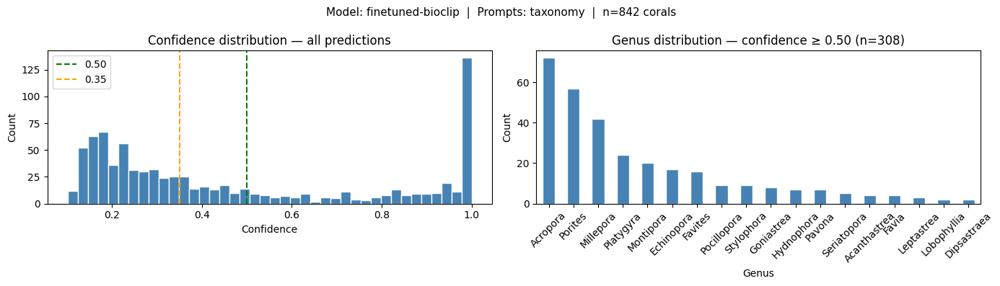

💾 Confidence plot saved.


In [ ]:
# ======================================
# CELL 4: Weak Labeling with BioCLIP / BioCLIP-2 (ReefNet)
# ======================================
import os
import torch
import cv2
import json
import numpy as np
import pandas as pd
from tqdm import tqdm
from PIL import Image
import open_clip
import pycocotools.mask as mask_util
import matplotlib.pyplot as plt
import random


# ── 1. MODEL SETUP ──────────────────────────────────────────────────────────
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")

MODEL_IDS = {
    "finetuned-bioclip": ("open_clip",    "hf-hub:ReefNet/finetuned-bioclip"),
    "bioclip2":          ("open_clip",    "hf-hub:imageomics/bioclip-2"),
    "siglip2":           ("transformers", "google/siglip2-so400m-patch14-384"),
}
if MODEL_VERSION not in MODEL_IDS:
    raise ValueError(f"Unknown MODEL_VERSION: {MODEL_VERSION}. Choose from {list(MODEL_IDS)}")

model_backend, model_id = MODEL_IDS[MODEL_VERSION]
print(f"Loading model: {model_id}  (backend: {model_backend})")

if model_backend == "open_clip":
    model, _, preprocess_val = open_clip.create_model_and_transforms(model_id)
    tokenizer = open_clip.get_tokenizer(model_id)
    siglip_processor = None
elif model_backend == "transformers":
    from transformers import AutoProcessor, AutoModel
    siglip_processor = AutoProcessor.from_pretrained(model_id)
    model = AutoModel.from_pretrained(model_id)
    tokenizer = None
    preprocess_val = None

model = model.to(device)
model.eval()
print(f"✅ Model loaded: {MODEL_VERSION}")

# ── 2. GENERA + THREE PROMPT STYLES ─────────────────────────────────────────
# Style A — full Linnaean taxonomy (primary training format for BioCLIP)
genera_taxonomy = {
    "Platygyra":    "Animalia Cnidaria Anthozoa Scleractinia Merulinidae Platygyra",
    "Acropora":     "Animalia Cnidaria Anthozoa Scleractinia Acroporidae Acropora",
    "Stylophora":   "Animalia Cnidaria Anthozoa Scleractinia Pocilloporidae Stylophora",
    "Millepora":    "Animalia Cnidaria Hydrozoa Anthoathecata Milleporidae Millepora",
    "Favites":      "Animalia Cnidaria Anthozoa Scleractinia Faviidae Favites",
    "Dipsastraea":  "Animalia Cnidaria Anthozoa Scleractinia Merulinidae Dipsastraea",
    "Favia":        "Animalia Cnidaria Anthozoa Scleractinia Faviidae Favia",
    "Echinopora":   "Animalia Cnidaria Anthozoa Scleractinia Faviidae Echinopora",
    "Hydnophora":   "Animalia Cnidaria Anthozoa Scleractinia Merulinidae Hydnophora",
    "Porites":      "Animalia Cnidaria Anthozoa Scleractinia Poritidae Porites",
    "Acanthastrea": "Animalia Cnidaria Anthozoa Scleractinia Lobophylliidae Acanthastrea",
    "Cyphastrea":   "Animalia Cnidaria Anthozoa Scleractinia Faviidae Cyphastrea",
    "Goniastrea":   "Animalia Cnidaria Anthozoa Scleractinia Faviidae Goniastrea",
    "Seriatopora":  "Animalia Cnidaria Anthozoa Scleractinia Pocilloporidae Seriatopora",
    "Pocillopora":  "Animalia Cnidaria Anthozoa Scleractinia Pocilloporidae Pocillopora",
    "Montipora":    "Animalia Cnidaria Anthozoa Scleractinia Acroporidae Montipora",
    "Leptastrea":   "Animalia Cnidaria Anthozoa Scleractinia Faviidae Leptastrea",
    "Galaxea":      "Animalia Cnidaria Anthozoa Scleractinia Euphylliidae Galaxea",
    "Lobophyllia":  "Animalia Cnidaria Anthozoa Scleractinia Lobophylliidae Lobophyllia",
    "Pavona":       "Animalia Cnidaria Anthozoa Scleractinia Agariciidae Pavona",
}

# Style B — morphological descriptions (aligns with Veron book text used in ReefNet fine-tune)
genera_descriptive = {
    "Platygyra":    "underwater photo of Platygyra brain coral with maze-like ridges and valleys",
    "Acropora":     "underwater photo of Acropora coral with branching or tabulate form and a single large corallite at each branch tip",
    "Stylophora":   "underwater photo of Stylophora coral with club-shaped lumpy compact branches",
    "Millepora":    "underwater photo of Millepora fire coral with smooth surface and tiny pores forming upright blade-like plates or branching columns without visible corallites",
    "Favites":      "underwater photo of Favites coral with honeycomb pattern of angular corallites with shared walls between adjacent polyps",
    "Dipsastraea": "underwater photo of Dipsastraea coral with rounded separate polyp mounds",
    "Favia": "underwater photo of Favia coral with rounded clearly separated corallites",
    "Echinopora":   "underwater photo of Echinopora coral with thin delicate plating sheets or irregular branching with small projecting corallites",
    "Hydnophora":   "underwater photo of Hydnophora coral with distinctive sharp pointed monticules projecting from surface",
    "Porites":      "underwater photo of Porites coral with very fine small porous uniform texture on massive or branching colony",
    "Acanthastrea": "underwater photo of Acanthastrea coral with large fleshy colorful separate polyps",
    "Cyphastrea":   "underwater photo of Cyphastrea coral with very small corallites embedded in smooth encrusting surface",
    "Goniastrea":   "underwater photo of Goniastrea coral with meandering brain-like valleys or tightly packed rounded corallites on encrusting surface",
    "Seriatopora":  "underwater photo of Seriatopora coral with very thin needle-like delicate branches and pointed tips",
    "Pocillopora":  "underwater photo of Pocillopora coral with cauliflower-like warty compact branches",
    "Montipora":    "underwater photo of Montipora coral with thin smooth encrusting plating sheets or thin finger-like branches with very small corallites",
    "Leptastrea":   "underwater photo of Leptastrea coral with small tightly packed encrusting corallites",
    "Galaxea":      "underwater photo of Galaxea coral with long separate tubular corallites and star-shaped polyps with bright white tips",
    "Lobophyllia":  "underwater photo of Lobophyllia coral with large fleshy lobed polyps",
    "Pavona":       "underwater photo of Pavona coral with thin leaf-like or vertical plates and fine surface texture",
}

# Style C — common name anchored to genus name
# BioCLIP was trained with mixed text types including common names,
# so this provides a third independent embedding direction per genus.
genera_common = {
    "Platygyra":    "brain coral Platygyra",
    "Acropora":     "staghorn coral Acropora",
    "Stylophora":   "club finger coral Stylophora",
    "Millepora":    "fire coral Millepora",
    "Favites":      "moon coral Favites",
    "Dipsastraea":  "pineapple coral Dipsastraea",
    "Favia":        "star coral Favia",
    "Echinopora":   "chalice coral Echinopora",
    "Hydnophora":   "velvet horn coral Hydnophora",
    "Porites":      "boulder coral Porites",
    "Acanthastrea": "button coral Acanthastrea",
    "Cyphastrea":   "encrusting pore coral Cyphastrea",
    "Goniastrea":   "wall brain coral Goniastrea",
    "Seriatopora":  "bird nest coral Seriatopora",
    "Pocillopora":  "cauliflower coral Pocillopora",
    "Montipora":    "velvet plate coral Montipora",
    "Leptastrea":   "dwarf cup coral Leptastrea",
    "Galaxea":      "galaxy coral Galaxea",
    "Lobophyllia":  "lobed brain coral Lobophyllia",
    "Pavona":       "cactus coral Pavona",
}


genera_hybrid = {
    # Update this one line in your hybrid dictionary:
    "Platygyra": "Animalia Cnidaria Anthozoa Scleractinia Merulinidae Platygyra brain coral with maze-like ridges and valleys",
    "Acropora":     "Animalia Cnidaria Anthozoa Scleractinia Acroporidae Acropora",
    "Stylophora":   "Animalia Cnidaria Anthozoa Scleractinia Pocilloporidae Stylophora",
    "Millepora":    "Animalia Cnidaria Hydrozoa Anthoathecata Milleporidae Millepora",
    "Favites":      "Animalia Cnidaria Anthozoa Scleractinia Faviidae Favites",
    "Dipsastraea":  "Animalia Cnidaria Anthozoa Scleractinia Merulinidae Dipsastraea",
    "Favia":        "Animalia Cnidaria Anthozoa Scleractinia Faviidae Favia",
    "Echinopora":   "Animalia Cnidaria Anthozoa Scleractinia Faviidae Echinopora",
    "Hydnophora":   "Animalia Cnidaria Anthozoa Scleractinia Merulinidae Hydnophora",
    "Porites":      "Animalia Cnidaria Anthozoa Scleractinia Poritidae Porites",
}

# Update your master list to pull from the hybrid keys
genera = list(genera_taxonomy.keys())

# ── 3. TEXT ENCODING WITH OPTIONAL ENSEMBLE ──────────────────────────────────
def encode_prompt_list(prompt_list):
    """Encode a list of text prompts → normalised feature matrix (n_classes × dim)."""
    if model_backend == "open_clip":
        tokens = tokenizer(prompt_list).to(device)
        with torch.no_grad():
            feats = model.encode_text(tokens)
    elif model_backend == "transformers":
        inputs = siglip_processor(
            text=prompt_list, return_tensors="pt", padding="max_length"
        ).to(device)
        with torch.no_grad():
            feats = model.get_text_features(**inputs)

            # --- FIX: Extract the tensor from the output object ---
            if not isinstance(feats, torch.Tensor):
                feats = feats.pooler_output

    feats /= feats.norm(dim=-1, keepdim=True)
    return feats

if PROMPT_FORMAT == "taxonomy":
    if model_backend == "transformers":
        print("⚠️  taxonomy format not recommended for SigLIP 2 — switching to descriptive")
        text_prompts  = [genera_descriptive[g] for g in genera]
    else:
        text_prompts  = [genera_taxonomy[g] for g in genera]
    text_features = encode_prompt_list(text_prompts)
    print(f"Using prompt format: taxonomy")
    print(f"Example: {text_prompts[0]}")

elif PROMPT_FORMAT == "descriptive":
    text_prompts  = [genera_descriptive[g] for g in genera]
    text_features = encode_prompt_list(text_prompts)
    print(f"Using prompt format: descriptive")
    print(f"Example: {text_prompts[0]}")

elif PROMPT_FORMAT == "ensemble":
    if model_backend == "transformers":
        # SigLIP 2: skip taxonomy (not trained on Linnaean strings), use 2-way ensemble
        feats_desc = encode_prompt_list([genera_descriptive[g] for g in genera])
        feats_cmn  = encode_prompt_list([genera_common[g]      for g in genera])
        text_features = (feats_desc + feats_cmn) / 2.0
        print("Using prompt format: ensemble (descriptive + common names) — taxonomy skipped for SigLIP 2")
    else:
        feats_tax  = encode_prompt_list([genera_taxonomy[g]    for g in genera])
        feats_desc = encode_prompt_list([genera_descriptive[g] for g in genera])
        feats_cmn  = encode_prompt_list([genera_common[g]      for g in genera])
        text_features = (feats_tax + feats_desc + feats_cmn) / 3.0
        print("Using prompt format: ensemble (taxonomy + descriptive + common names)")
    text_features /= text_features.norm(dim=-1, keepdim=True)
elif PROMPT_FORMAT == "hybrid":
    text_prompts  = [genera_hybrid[g] for g in genera]
    text_features = encode_prompt_list(text_prompts)
    print(f"Using prompt format: hybrid (custom per-genus prompts)")
    print(f"Example Platygyra: {genera_hybrid['Platygyra']}")
    print(f"Example Acropora: {genera_hybrid['Acropora']}")
else:
    raise ValueError(f"Unknown PROMPT_FORMAT: {PROMPT_FORMAT}")

print(f"\n✅ Text features encoded for {len(genera)} genera  |  shape: {text_features.shape}")


# ── 4. CROP FUNCTIONS ───────────────────────────────────────────────


def get_crop(img, bbox, padding_pct=0.15):
    x, y, w, h = map(int, bbox)
    pad_w = int(w * padding_pct)
    pad_h = int(h * padding_pct)
    x1 = max(0, x - pad_w)
    y1 = max(0, y - pad_h)
    x2 = min(img.shape[1], x + w + pad_w)
    y2 = min(img.shape[0], y + h + pad_h)
    crop = img[y1:y2, x1:x2]
    if crop.size == 0:
        return None
    return crop

def get_masked_crop(img, bbox, rle, padding_pct=0.05, background="black", min_visible=500):
    mask = decode_rle(rle)
    if mask.shape != img.shape[:2]:
        mask = cv2.resize(mask.astype(np.uint8),
                          (img.shape[1], img.shape[0]),
                          interpolation=cv2.INTER_NEAREST).astype(bool)
    bg_val = {"black": 0, "gray": 128, "white": 255}.get(background, 0)
    masked_img = img.copy()
    masked_img[~mask] = bg_val
    x, y, w, h = map(int, bbox)
    pad_w = int(w * padding_pct)
    pad_h = int(h * padding_pct)
    x1 = max(0, x - pad_w)
    y1 = max(0, y - pad_h)
    x2 = min(img.shape[1], x + w + pad_w)
    y2 = min(img.shape[0], y + h + pad_h)
    crop = masked_img[y1:y2, x1:x2]
    if crop.size == 0:
        return None
    visible = np.any(crop != bg_val, axis=2).sum()
    if visible < min_visible:
        return None
    return crop

def is_sharp_enough(crop, threshold=50.0):
    gray = cv2.cvtColor(crop, cv2.COLOR_RGB2GRAY)
    return cv2.Laplacian(gray, cv2.CV_64F).var() >= threshold





# ── 5. CONFIGURATION ─────────────────────────────────────────────────────────
BATCH_SIZE = 64
crop_mode  = "masked" if USE_MASK else "bbox"
sample_tag = SAMPLE_MODE if SAMPLE_ONLY else "full"
# Filename encodes all three key settings so runs never overwrite each other
output_csv = os.path.join(
    run_dir,
    f'coral_weak_labels_{MODEL_VERSION}_{PROMPT_FORMAT}_{crop_mode}_{sample_tag}.csv'
)
print(f"\nOutput: {output_csv}")


# ── 6. RESUME LOGIC ──────────────────────────────────────────────────────────
processed_ids = set()
if RESUME and not SAMPLE_ONLY and os.path.exists(output_csv):
    existing      = pd.read_csv(output_csv)
    processed_ids = set(existing['coral_id'])
    print(f"↩️  Resuming: {len(processed_ids)} masks already done, skipping them")


# ── 7. FILE LIST ─────────────────────────────────────────────────────────────

if not SAMPLE_ONLY:
    json_files = json_files_all
    print(f"🚀 Full run: {len(json_files)} files")
else:
    if SAMPLE_MODE == "first":
        json_files = json_files_all[:SAMPLE_SIZE]
    elif SAMPLE_MODE == "random":
        random.seed(RANDOM_SEED)
        json_files = random.sample(json_files_all, min(SAMPLE_SIZE, len(json_files_all)))
    elif SAMPLE_MODE == "stratified":
        from collections import defaultdict
        groups = defaultdict(list)
        for f in json_files_all:
            prefix = f.split('.')[0].rstrip('0123456789')
            groups[prefix].append(f)
        per_group  = max(1, SAMPLE_SIZE // len(groups))
        json_files = []
        random.seed(RANDOM_SEED)
        for prefix, files in sorted(groups.items()):
            json_files.extend(random.sample(files, min(per_group, len(files))))
        json_files = json_files[:SAMPLE_SIZE]
    elif SAMPLE_MODE == "best":
        json_files = df_counts.head(SAMPLE_SIZE)['file'].tolist()
    print(f"🔬 Sample mode: {SAMPLE_MODE} — {len(json_files)} files")


# ── 8. PROCESSING LOOP ───────────────────────────────────────────────────────
metadata_list   = []
scores_list     = []
batch_tensors   = []
batch_meta_temp = []

def process_batch(tensors, metas):
    if not tensors:
        return
    batch_input = torch.stack(tensors).to(device)
    with torch.no_grad():
        if model_backend == "open_clip":
            image_features = model.encode_image(batch_input)
        else:  # transformers / SigLIP 2
            image_features = model.get_image_features(pixel_values=batch_input)
            # --- FIX: Extract the tensor from the output object ---
            if not isinstance(image_features, torch.Tensor):
                image_features = image_features.pooler_output
        image_features /= image_features.norm(dim=-1, keepdim=True)
        # SigLIP 2 uses sigmoid loss so softmax is less meaningful,
        # but softmax over our closed label set still gives comparable confidence scores
        similarity = (100.0 * image_features @ text_features.T).softmax(dim=-1)
    scores_list.append(similarity.cpu().numpy())
    metadata_list.extend(metas)



total_before_filter = 0
total_after_filter  = 0

for j_file in tqdm(json_files, desc="BioCLIP weak labeling"):
    path = os.path.join(json_dir, j_file)
    with open(path, 'r') as f:
        data = json.load(f)

    img_name = data['image']['file_name']
    img_path = os.path.join(data_path, img_name)
    if not os.path.exists(img_path):
        continue

    image = cv2.imread(img_path)
    if image is None:
        continue
    image = cv2.resize(image, (2560, 1920))
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    total_before_filter += len(data['annotations'])

    filtered_annos = filter_annotations(
        data['annotations'],
        min_area=MIN_AREA,
        containment_thresh=CONTAINMENT_THRESH,
        max_aspect_ratio=MAX_ASPECT_RATIO,
    )
    total_after_filter += len(filtered_annos)

    for anno in filtered_annos:
        if anno['id'] in processed_ids:
            continue

        if USE_MASK:
            crop_np = get_masked_crop(
                image, anno['bbox'], anno['segmentation'],
                padding_pct=MASK_PADDING_PCT,
                background=MASK_BACKGROUND,
            )
        else:
            crop_np = get_crop(image, anno['bbox'])

        if crop_np is None:
            continue
        if not is_sharp_enough(crop_np, threshold=SHARPNESS_THRESHOLD):
            continue

        crop_pil = Image.fromarray(crop_np)
        if model_backend == "open_clip":
            img_tensor = preprocess_val(crop_pil)
        else:  # transformers / SigLIP 2
            img_tensor = siglip_processor(
                images=crop_pil, return_tensors="pt"
            )['pixel_values'].squeeze(0)



        batch_tensors.append(img_tensor)
        batch_meta_temp.append({
            'image_name': img_name,
            'coral_id':   anno['id'],
            'bbox':       anno['bbox'],
            'area':       anno['area'],
        })

        if len(batch_tensors) >= BATCH_SIZE:
            process_batch(batch_tensors, batch_meta_temp)
            batch_tensors   = []
            batch_meta_temp = []

if batch_tensors:
    process_batch(batch_tensors, batch_meta_temp)

print(f"\nAnnotations before filtering: {total_before_filter}")
print(f"Annotations after filtering:  {total_after_filter} "
      f"({100*total_after_filter/max(total_before_filter,1):.1f}% kept)")


# ── 9. SAVE RESULTS ──────────────────────────────────────────────────────────
if not metadata_list:
    print("⚠️ Nothing new to save.")
else:
    df_meta    = pd.DataFrame(metadata_list)
    all_scores = np.vstack(scores_list)

    df_scores = pd.DataFrame(all_scores, columns=genera)
    df_scores['predicted_genus'] = df_scores.idxmax(axis=1)
    df_scores['confidence']      = df_scores[genera].max(axis=1)

    final_df = pd.concat([df_meta, df_scores], axis=1)

    if RESUME and not SAMPLE_ONLY and os.path.exists(output_csv):
        final_df.to_csv(output_csv, mode='a', header=False, index=False)
        print(f"✅ Appended {len(final_df)} corals")
    else:
        final_df.to_csv(output_csv, index=False)
        print(f"✅ Saved {len(final_df)} corals")

    print(f"📁 {output_csv}")
    print(f"\nPredicted genera distribution:")
    print(final_df['predicted_genus'].value_counts())
    print(f"\nMean confidence: {final_df['confidence'].mean():.3f}")
    print(f"High-confidence (≥0.50): {(final_df['confidence']>=0.5).sum()} / {len(final_df)}")


# ── 10. CONFIDENCE HISTOGRAM ─────────────────────────────────────────────────
    fig, axes = plt.subplots(1, 2, figsize=(14, 4))
    fig.suptitle(f"Model: {MODEL_VERSION}  |  Prompts: {PROMPT_FORMAT}  |  n={len(final_df)} corals",
             fontsize=11)

    axes[0].hist(final_df['confidence'], bins=40, color='steelblue', edgecolor='white')
    axes[0].axvline(0.50, color='green',  linestyle='--', label='0.50')
    axes[0].axvline(0.35, color='orange', linestyle='--', label='0.35')
    axes[0].set_xlabel('Confidence')
    axes[0].set_ylabel('Count')
    axes[0].set_title('Confidence distribution — all predictions')
    axes[0].legend()

    high_conf = final_df[final_df['confidence'] >= 0.50]
    if len(high_conf) > 0:
        high_conf['predicted_genus'].value_counts().plot(
            kind='bar', ax=axes[1], color='steelblue', edgecolor='white'
        )
        axes[1].set_title(f'Genus distribution — confidence ≥ 0.50 (n={len(high_conf)})')
        axes[1].set_xlabel('Genus')
        axes[1].set_ylabel('Count')
        axes[1].tick_params(axis='x', rotation=45)
    else:
        axes[1].text(0.5, 0.5, 'No predictions ≥ 0.50',
                     ha='center', va='center', transform=axes[1].transAxes)
        axes[1].set_title('Genus distribution — confidence ≥ 0.50')

    plt.tight_layout()
    plt.savefig(os.path.join(run_dir, f'confidence_dist_{MODEL_VERSION}_{PROMPT_FORMAT}.png'),
                dpi=150, bbox_inches='tight')
    plt.show()
    print("💾 Confidence plot saved.")

## Visual Precision Check per Genus

Displays all crops predicted as a chosen genus (`GENUS_TO_CHECK`), sorted by confidence. This is the key tool for estimating **precision** — by scrolling through, you can see whether the model's predictions for a given genus actually look correct. Particularly useful for genera like Platygyra where confusion with Goniastrea is common.

🔍 Platygyra: 32 crops (showing up to 60)
   Confidence range: 0.22 – 1.00
   Mean confidence:  0.75


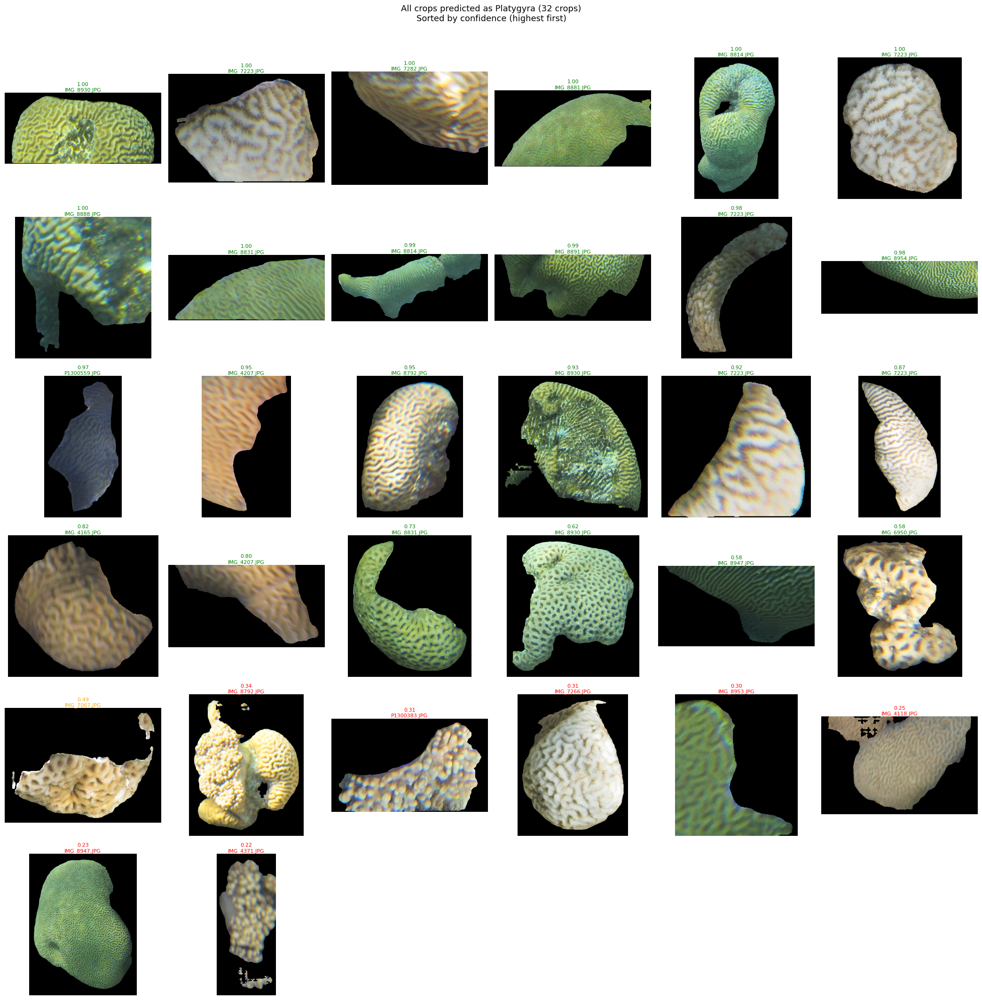

💾 Saved to precision_check_Platygyra.png


In [ ]:
# ======================================
# CELL: Visual precision check — show all crops predicted as GENUS_TO_CHECK
# ======================================
# Change this to any genus you want to inspect:
GENUS_TO_CHECK = "Platygyra"
MAX_SHOW = 60          # max crops to display (raise if needed)
COLS = 6               # columns in grid
# ======================================

import pandas as pd
import matplotlib.pyplot as plt
import cv2, os, json

df_check = pd.read_csv(output_csv)
df_genus = df_check[df_check['predicted_genus'] == GENUS_TO_CHECK].sort_values(
    'confidence', ascending=False
).head(MAX_SHOW).reset_index(drop=True)

print(f"🔍 {GENUS_TO_CHECK}: {len(df_genus)} crops (showing up to {MAX_SHOW})")
print(f"   Confidence range: {df_genus['confidence'].min():.2f} – {df_genus['confidence'].max():.2f}")
print(f"   Mean confidence:  {df_genus['confidence'].mean():.2f}")

if len(df_genus) == 0:
    print(f"⚠️ No crops predicted as {GENUS_TO_CHECK}")
else:
    n = len(df_genus)
    rows = -(-n // COLS)
    fig, axes = plt.subplots(rows, COLS, figsize=(3.5 * COLS, 3.5 * rows))
    if rows == 1 and COLS == 1:
        axes = [axes]
    elif rows == 1 or COLS == 1:
        axes = axes.flatten()
    else:
        axes = axes.flatten()

    for i, (_, row) in enumerate(df_genus.iterrows()):
        ax = axes[i]
        img_path = os.path.join(data_path, row['image_name'])
        image = cv2.imread(img_path)
        if image is None:
            ax.axis('off')
            continue

        image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
        image = cv2.resize(image, (2560, 1920))
        bbox = eval(row['bbox']) if isinstance(row['bbox'], str) else row['bbox']

        crop = None
        if USE_MASK:
            img_stem = os.path.splitext(row['image_name'])[0]
            json_path = os.path.join(json_dir, img_stem + '.json')
            rle = None
            if os.path.exists(json_path):
                with open(json_path, 'r') as f:
                    jdata = json.load(f)
                for anno in jdata['annotations']:
                    if anno['id'] == row['coral_id']:
                        rle = anno['segmentation']
                        break
            if rle is not None:
                crop = get_masked_crop(image, bbox, rle,
                                       padding_pct=MASK_PADDING_PCT,
                                       background=MASK_BACKGROUND)

        if crop is None:
            x, y, w, h = map(int, bbox)
            crop = image[max(0, y):y+h, max(0, x):x+w]

        ax.imshow(crop)
        ax.axis('off')

        conf = row['confidence']
        color = 'green' if conf >= 0.5 else 'orange' if conf >= 0.35 else 'red'
        ax.set_title(f"{conf:.2f}\n{row['image_name'][:12]}", fontsize=8, color=color, pad=2)

    for j in range(n, len(axes)):
        axes[j].axis('off')

    fig.suptitle(
        f"All crops predicted as {GENUS_TO_CHECK} ({n} crops)\n"
        f"Sorted by confidence (highest first)",
        fontsize=13, y=1.01
    )
    plt.tight_layout()
    plt.savefig(os.path.join(run_dir, f'precision_check_{GENUS_TO_CHECK}.png'),
                dpi=150, bbox_inches='tight')
    plt.show()
    print(f"💾 Saved to precision_check_{GENUS_TO_CHECK}.png")

## Visualization: Random Prediction Sample

Draws a random sample of classified corals and displays each crop with its predicted genus and confidence score. Color-coded titles: **green** (≥0.50), **orange** (≥0.35), **red** (<0.35). Provides a quick visual gut-check of overall model performance.

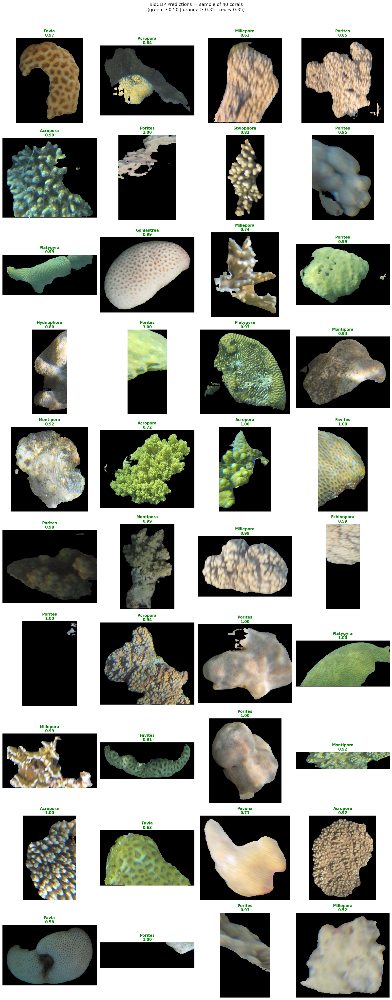

💾 Figure saved.


In [ ]:
# ======================================
# CELL: Visualize BioCLIP Predictions
# ======================================
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import cv2
import json
import os
import numpy as np

# CONTROLS
N_SAMPLES = 40          # total images to show
COLS = 4                # columns in the grid
MIN_CONFIDENCE = 0.5    # set e.g. 0.5 to show only confident predictions

# Load results
# change this line so it reads the correct output file
df = pd.read_csv(os.path.join(run_dir, f'coral_weak_labels_{MODEL_VERSION}_{PROMPT_FORMAT}_{crop_mode}.csv'))

if MIN_CONFIDENCE > 0:
    df = df[df['confidence'] >= MIN_CONFIDENCE]

# Sample randomly
sample = df.sample(n=min(N_SAMPLES, len(df)), random_state=42).reset_index(drop=True)

# Build grid
rows = (len(sample) + COLS - 1) // COLS
fig, axes = plt.subplots(rows, COLS, figsize=(COLS * 4, rows * 4))
axes = axes.flatten()

for i, row in sample.iterrows():
    ax = axes[i]

    img_path = os.path.join(data_path, row['image_name'])
    image = cv2.imread(img_path)
    if image is None:
        ax.axis('off')
        continue

    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
    image = cv2.resize(image, (2560, 1920))

    bbox = eval(row['bbox']) if isinstance(row['bbox'], str) else row['bbox']

    if USE_MASK:
        img_stem  = os.path.splitext(row['image_name'])[0]
        json_path = os.path.join(json_dir, img_stem + '.json')
        rle = None
        if os.path.exists(json_path):
            with open(json_path, 'r') as f:
                jdata = json.load(f)
            for anno in jdata['annotations']:
                if anno['id'] == row['coral_id']:
                    rle = anno['segmentation']
                    break
        crop = get_masked_crop(image, bbox, rle,
                           padding_pct=MASK_PADDING_PCT,
                           background=MASK_BACKGROUND) if rle else get_crop(image, bbox)
        if crop is None:
            crop = get_crop(image, bbox)   # fallback for near-empty masks
    else:
        crop = get_crop(image, bbox)

    if crop is None:
        ax.axis('off')
        continue

    ax.imshow(crop)
    ax.axis('off')

    conf = row['confidence']
    color = 'green' if conf >= 0.5 else 'orange' if conf >= 0.35 else 'red'
    ax.set_title(
        f"{row['predicted_genus']}\n{conf:.2f}",
        fontsize=11, fontweight='bold', color=color, pad=4
    )


# Hide unused axes
for j in range(len(sample), len(axes)):
    axes[j].axis('off')

plt.suptitle(
    f"BioCLIP Predictions — sample of {len(sample)} corals\n"
    f"(green ≥ 0.50 | orange ≥ 0.35 | red < 0.35)",
    fontsize=13, y=1.01
)
plt.tight_layout()
plt.savefig(os.path.join(run_dir, 'bioclip_sample_predictions.png'),
            dpi=150, bbox_inches='tight')
plt.show()
print("💾 Figure saved.")

## Visualization: Predictions Grouped by Genus

Sorts all predictions by genus and then by confidence (descending), samples a balanced subset, and renders the actual masked crops in a grid. This makes it easy to spot systematic misclassifications — if a genus block contains visually wrong corals, the model or the prompt needs tuning.

/tmp/ipykernel_1697/2307880185.py:16: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  df_sorted = df_sorted.groupby("predicted_genus", group_keys=False).apply(


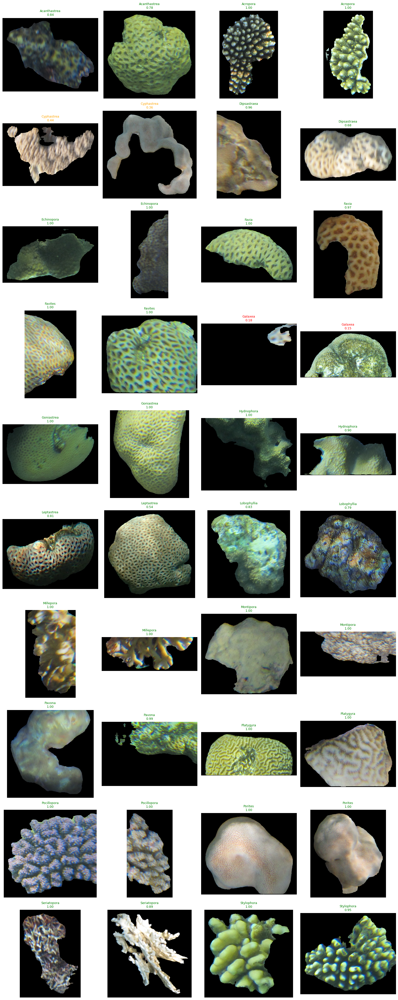

In [ ]:
# ======================================
# CELL: Visualization grid — sorted by predicted genus, shows actual masked crop
# ======================================
import matplotlib.pyplot as plt
import cv2, os, json

MIN_CONFIDENCE = 0.0
N_SAMPLES = 40

df_review = pd.read_csv(output_csv)
if MIN_CONFIDENCE > 0:
    df_review = df_review[df_review['confidence'] >= MIN_CONFIDENCE]

df_sorted = df_review.sort_values(by=["predicted_genus", "confidence"], ascending=[True, False])
if N_SAMPLES is not None:
    df_sorted = df_sorted.groupby("predicted_genus", group_keys=False).apply(
        lambda g: g.head(max(1, N_SAMPLES // df_sorted["predicted_genus"].nunique()))
    )
    df_sorted = df_sorted.head(N_SAMPLES) if len(df_sorted) > N_SAMPLES else df_sorted

# Need segmentation RLE for each row — merge back in from the source JSONs
# since bbox/area/coral_id alone aren't enough to reconstruct the mask
def get_segmentation_for(image_name, coral_id):
    # find the matching json file for this image (adjust if you have a faster lookup)
    for j_file in json_files_all:
        path = os.path.join(json_dir, j_file)
        with open(path, 'r') as f:
            data = json.load(f)
        if data['image']['file_name'] != image_name:
            continue
        for anno in data['annotations']:
            if anno['id'] == coral_id:
                return anno['segmentation']
    return None

n = len(df_sorted)
n_cols = 4
n_rows = -(-n // n_cols)
fig, axes = plt.subplots(n_rows, n_cols, figsize=(4 * n_cols, 4 * n_rows))
axes = axes.flatten()

for ax, (_, row) in zip(axes, df_sorted.iterrows()):
    img_path = os.path.join(data_path, row["image_name"])
    image = cv2.imread(img_path)
    image = cv2.resize(image, (2560, 1920))
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    bbox = eval(row["bbox"]) if isinstance(row["bbox"], str) else row["bbox"]

    rle = get_segmentation_for(row["image_name"], row["coral_id"])
    if rle is not None:
        crop = get_masked_crop(image, bbox, rle, padding_pct=MASK_PADDING_PCT, background=MASK_BACKGROUND)
    else:
        crop = None

    if crop is None:
        # fallback to plain bbox crop if mask lookup failed
        x, y, w, h = map(int, bbox)
        crop = image[max(0,y):y+h, max(0,x):x+w]

    ax.imshow(crop)
    color = "green" if row["confidence"] >= 0.5 else ("orange" if row["confidence"] >= 0.35 else "red")
    ax.set_title(f"{row['predicted_genus']}\n{row['confidence']:.2f}", fontsize=9, color=color)
    ax.axis("off")

for ax in axes[n:]:
    ax.axis("off")

# fig.suptitle("BioCLIP Predictions — grouped by predicted genus (actual masked input shown)\n(green ≥ 0.50 | orange ≥ 0.35 | red < 0.35)", fontsize=12)
plt.tight_layout()
plt.savefig(os.path.join(run_dir, "predictions_grouped_by_genus_masked.png"), dpi=150, bbox_inches="tight")
plt.show()

# Compare models and approaches


## Model Comparison: True vs. Predicted Genus Distribution

Auto-discovers all `coral_weak_labels_*.csv` result files in the run directory and compares each model/prompt combination against the ground-truth genus proportions. Plots a grouped bar chart, computes over/under-prediction ratios, and identifies the most common runner-up confusions per run.

Found 6 result files:
 - coral_weak_labels_bioclip2_ensemble_masked.csv
 - coral_weak_labels_finetuned-bioclip_descriptive_masked.csv
 - coral_weak_labels_finetuned-bioclip_ensemble_masked.csv
 - coral_weak_labels_finetuned-bioclip_hybrid_masked.csv
 - coral_weak_labels_finetuned-bioclip_taxonomy_masked.csv
 - coral_weak_labels_siglip2_descriptive_masked.csv


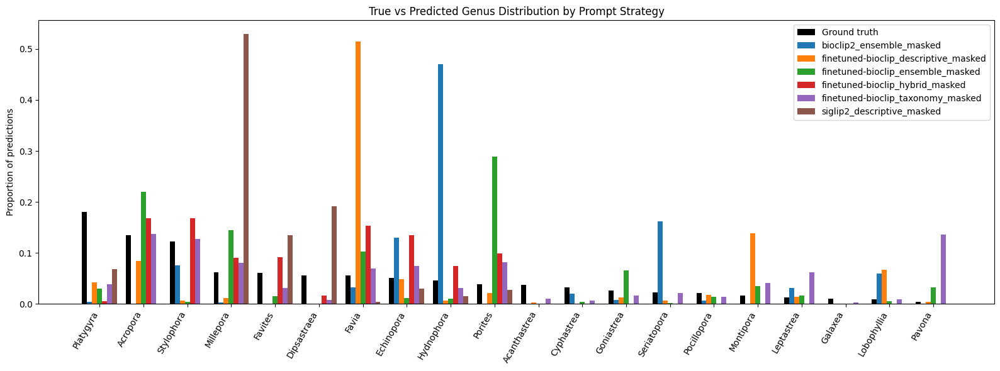


Over/under-prediction ratio (predicted ÷ expected), 1.0 = perfect match

              gt_count  bioclip2_ensemble_masked_pred  bioclip2_ensemble_masked_ratio  finetuned-bioclip_descriptive_masked_pred  finetuned-bioclip_descriptive_masked_ratio  finetuned-bioclip_ensemble_masked_pred  finetuned-bioclip_ensemble_masked_ratio  finetuned-bioclip_hybrid_masked_pred  finetuned-bioclip_hybrid_masked_ratio  finetuned-bioclip_taxonomy_masked_pred  finetuned-bioclip_taxonomy_masked_ratio  siglip2_descriptive_masked_pred  siglip2_descriptive_masked_ratio
genus                                                                                                                                                                                                                                                                                                                                                                                                                                                          

In [ ]:
# ======================================
# CELL: True vs Predicted Genus Distribution — read everything from disk
# ======================================
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import os, glob

# ── 1. GROUND TRUTH ───────────────────────────────────────────────────────
# Save this once from your table (Category, Observation, #) e.g.:
#   ground_truth.to_csv(os.path.join(base_path, 'ground_truth_genus_counts.csv'), index=False)
gt_path = os.path.join(base_path, 'ground_truth_genus_counts.csv')
df_gt = pd.read_csv(gt_path)   # columns: Category, Observation, #, Pi (or just Observation, #)
df_gt = df_gt.rename(columns={"Observation": "genus", "#": "count"})

# ── 2. AUTO-DISCOVER ALL RUN CSVs IN THIS run_dir ────────────────────────
result_files = sorted(glob.glob(os.path.join(run_dir, "coral_weak_labels_*.csv")))
print(f"Found {len(result_files)} result files:")
for f in result_files:
    print(" -", os.path.basename(f))

run_dfs = {}
for f in result_files:
    # extract a readable run name from filename, e.g. "finetuned-bioclip_taxonomy_masked"
    run_name = os.path.basename(f).replace("coral_weak_labels_", "").replace(".csv", "")
    run_dfs[run_name] = pd.read_csv(f)

# Restrict ground truth to genera actually present as prediction columns in the runs
# (assumes all runs used the same 20-genus label set; grab genus list from any one run)
sample_df = next(iter(run_dfs.values()))
non_genus_cols = {"image_name", "coral_id", "bbox", "area", "predicted_genus", "confidence"}
genera = [c for c in sample_df.columns if c not in non_genus_cols]

df_gt = df_gt[df_gt["genus"].isin(genera)].set_index("genus").reindex(genera).fillna(0)
gt_total = df_gt["count"].sum()
gt_prop = df_gt["count"] / gt_total

# ── 3. PER-RUN PROPORTIONS + COUNTS (from predicted_genus column) ───────────
run_counts = {name: df["predicted_genus"].value_counts().reindex(genera, fill_value=0)
              for name, df in run_dfs.items()}
run_props  = {name: counts / counts.sum() for name, counts in run_counts.items()}

# ── 4. GROUPED BAR CHART ─────────────────────────────────────────────────────
n_groups = 1 + len(run_props)
bar_width = 0.8 / n_groups
x = np.arange(len(genera))

fig, ax = plt.subplots(figsize=(16, 6))
ax.bar(x - 0.4 + bar_width/2, gt_prop.values, width=bar_width, label="Ground truth", color="black")

colors = plt.cm.tab10.colors
for i, (run_name, props) in enumerate(run_props.items()):
    offset = -0.4 + bar_width/2 + bar_width * (i + 1)
    ax.bar(x + offset, props.values, width=bar_width, label=run_name, color=colors[i % len(colors)])

ax.set_xticks(x); ax.set_xticklabels(genera, rotation=60, ha="right")
ax.set_ylabel("Proportion of predictions")
ax.set_title("True vs Predicted Genus Distribution by Prompt Strategy")
ax.legend()
plt.tight_layout()
plt.savefig(os.path.join(run_dir, "true_vs_predicted_distribution.png"), dpi=150, bbox_inches="tight")
plt.show()

# ── 5. RATIO TABLE ────────────────────────────────────────────────────────
df_ratio = pd.DataFrame({"gt_count": df_gt["count"]})
for run_name, counts in run_counts.items():
    n_run = counts.sum()
    expected = gt_prop * n_run
    df_ratio[f"{run_name}_pred"] = counts
    df_ratio[f"{run_name}_ratio"] = (counts / expected).round(2)

print("\nOver/under-prediction ratio (predicted ÷ expected), 1.0 = perfect match\n")
print(df_ratio.to_string())

ratio_cols = [c for c in df_ratio.columns if c.endswith("_ratio")]
flagged = df_ratio[df_ratio[ratio_cols].apply(lambda r: any((r < 0.3) | (r > 3.0) | r.isna()), axis=1)]
print("\n🚩 Genera with ratio < 0.3 or > 3.0 in at least one run:")
print(flagged[["gt_count"] + ratio_cols].to_string())

# ── 6. BONUS: confidence calibration + runner-up confusion per run ──────────
non_genus_cols = {"image_name", "coral_id", "bbox", "area", "predicted_genus", "confidence"}

for run_name, df in run_dfs.items():
    # genus score columns specific to THIS file, not the global `genera` list
    score_cols = [c for c in df.columns if c not in non_genus_cols]

    print(f"\n── {run_name} ── ({len(score_cols)} genus columns, {len(df)} corals)")

    if len(score_cols) < 2:
        print("  ⚠️  Skipping — fewer than 2 genus score columns found, can't compute runner-up.")
        continue

    missing_from_main = set(genera) - set(score_cols)
    if missing_from_main:
        print(f"  ⚠️  Note: this run is missing genus columns present elsewhere: {sorted(missing_from_main)}")

    top2 = df[score_cols].apply(lambda row: row.nlargest(2).index[1], axis=1)
    confusion = pd.DataFrame({"predicted": df["predicted_genus"], "runner_up": top2})
    print("  Most common (predicted, runner-up) pairs:")
    print(confusion.value_counts().head(8).to_string())

## Single-Image Inspector

Deep-dive into one image at a time. Shows the original photo, a purple overlay of all SAM masks, and bounding boxes with IoU/stability scores. Change `IMAGE_STEM` to inspect any image. Useful for debugging mask quality or checking whether the segmentation parameters are appropriate.

Image: IMG_4033  |  Size: 2560x1920  |  Annotations: 15


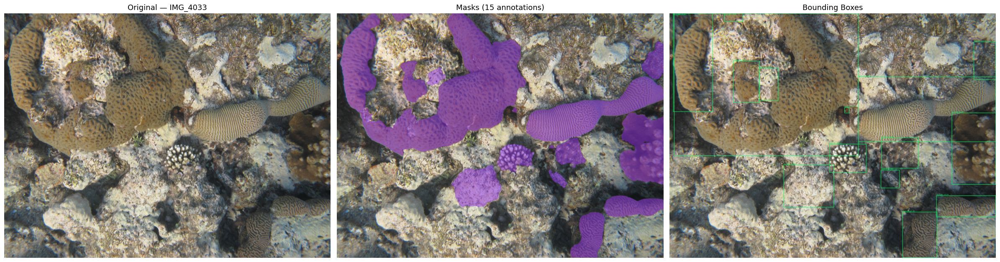

💾 Saved to inspect_IMG_4033.png

Annotation stats for IMG_4033:
 id   area  bbox_w  bbox_h  aspect_ratio  predicted_iou  stability
 14 725679    1445    1117          1.29          0.804      0.628
 11 223605    1077     510          2.11          0.759      0.566
  9 157043     344     562          1.63          0.854      0.812
  7 141271     309     771          2.50          0.846      0.822
 13  93382     393     333          1.18          0.840      0.855
  2  66365     270     358          1.33          0.861      0.905
  1  60183     465     168          2.77          0.885      0.936
  0  44121     288     222          1.30          0.928      0.920
 10  37643     288     238          1.21          0.760      0.682
  6  37329     205     326          1.59          0.880      0.919
  8  33482     171     296          1.73          0.610      0.790
 12  13036     150     255          1.70          0.725      0.674
  3   9184     145     141          1.03          0.749      0.88

In [ ]:
# ======================================
# CELL: Inspect Single Image — Masks & BBoxes
# ======================================
import os
import cv2
import json
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import pycocotools.mask as mask_util

# ======================================
# INPUT — change this
# ======================================
IMAGE_STEM = "IMG_4033"   # no extension
# ======================================



# Find the image file (try common extensions)
img_path = None
for ext in ['.jpg', '.jpeg', '.JPG', '.JPEG', '.png', '.PNG']:
    candidate = os.path.join(data_path, IMAGE_STEM + ext)
    if os.path.exists(candidate):
        img_path = candidate
        break

if img_path is None:
    raise FileNotFoundError(f"No image found for {IMAGE_STEM} in {data_path}")

json_path = os.path.join(json_dir, IMAGE_STEM + ".json")
if not os.path.exists(json_path):
    raise FileNotFoundError(f"No JSON found at {json_path}")

# Load image
image = cv2.imread(img_path)
image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

# Resize the image to match the dimensions the bounding boxes were generated for
# (Assuming the CSV coordinates come from the 2560x1920 JSON annotations)
image = cv2.resize(image, (2560, 1920))

# Get the bounding box crop
h, w = image.shape[:2]
# Load JSON
with open(json_path, 'r') as f:
    data = json.load(f)

annotations = data['annotations']
print(f"Image: {IMAGE_STEM}  |  Size: {w}x{h}  |  Annotations: {len(annotations)}")

# ======================================
# BUILD OVERLAYS
# ======================================

# --- Masks overlay ---
mask_overlay = image.copy().astype(np.float32)
combined_mask = np.zeros((h, w), dtype=bool)

for anno in annotations:
    rle = anno['segmentation']
    # Ensure counts is bytes for pycocotools
    if isinstance(rle['counts'], str):
        rle = {'size': rle['size'], 'counts': rle['counts'].encode('utf-8')}
    decoded = mask_util.decode(rle).astype(bool)
    combined_mask |= decoded

# Paint living tissue purple
purple = np.array([138, 43, 226], dtype=np.float32)
mask_overlay[combined_mask] = (
    mask_overlay[combined_mask] * 0.5 + purple * 0.5
)
mask_overlay = mask_overlay.astype(np.uint8)

# --- BBox overlay: draw on a copy ---
bbox_image = image.copy()
for anno in annotations:
    x, y, bw, bh = [int(v) for v in anno['bbox']]
    iou   = anno.get('predicted_iou', None)
    stab  = anno.get('stability_score', None)
    label = f"iou:{iou:.2f} s:{stab:.2f}" if iou and stab else ""
    cv2.rectangle(bbox_image, (x, y), (x + bw, y + bh), (0, 255, 100), 2)
    if label:
        cv2.putText(bbox_image, label, (x, max(y - 4, 12)),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.4, (0, 255, 100), 1)

# ======================================
# PLOT
# ======================================
fig, axes = plt.subplots(1, 3, figsize=(24, 8))

axes[0].imshow(image)
axes[0].set_title(f"Original — {IMAGE_STEM}", fontsize=13)
axes[0].axis('off')

axes[1].imshow(mask_overlay)
axes[1].set_title(f"Masks ({len(annotations)} annotations)", fontsize=13)
axes[1].axis('off')

axes[2].imshow(bbox_image)
axes[2].set_title("Bounding Boxes", fontsize=13)
axes[2].axis('off')

plt.tight_layout()
plt.savefig(os.path.join(run_dir, f"inspect_{IMAGE_STEM}.png"),
            dpi=150, bbox_inches='tight')
plt.show()
print(f"💾 Saved to inspect_{IMAGE_STEM}.png")

# ======================================
# STATS TABLE
# ======================================
rows = []
for anno in annotations:
    x, y, bw, bh = anno['bbox']
    rows.append({
        'id':             anno['id'],
        'area':           anno['area'],
        'bbox_w':         int(bw),
        'bbox_h':         int(bh),
        'aspect_ratio':   round(max(bw, bh) / max(min(bw, bh), 1), 2),
        'predicted_iou':  round(anno.get('predicted_iou', 0), 3),
        'stability':      round(anno.get('stability_score', 0), 3),
    })

df = pd.DataFrame(rows).sort_values('area', ascending=False)
print(f"\nAnnotation stats for {IMAGE_STEM}:")
print(df.to_string(index=False))

---

# Scratch / Debug Cells

Cells below are not part of the main pipeline. They were used during development for debugging, sanity checks, and one-off investigations.

progress:
attempted 3 models (bioclip2, bioclip reefnet finetuned, google siglip)
bioclip finetuned performs best
removed to 10 most common genus for better results
option: all corals under threshold of confidence will be classified as "other"
ensemble has best results

# Debug platygyra

In [ ]:
import random
import numpy as np

random.seed(RANDOM_SEED)
json_files_random = random.sample(json_files_all, 50)

def mean_annotations(file_list):
    counts = []
    for f in file_list:
        with open(os.path.join(json_dir, f)) as fh:
            d = json.load(fh)
        counts.append(len(d['annotations']))
    return np.mean(counts), counts

best_mean, best_counts = mean_annotations(json_files)          # your actual "best" 50 from the taxonomy run
random_mean, random_counts = mean_annotations(json_files_random)

print(f"Best-50   mean annotations/image (raw): {best_mean:.1f}")
print(f"Random-50 mean annotations/image (raw): {random_mean:.1f}")

# Sanity check against df_counts directly too, since it already has this cached
print(f"\ndf_counts['raw'].describe() — full dataset:")
print(df_counts['raw'].describe())
print(f"\nBest-50 files' 'raw' column (should match df_counts.head(50)):")
print(df_counts.head(50)['raw'].describe())

## Quick Look: Annotation Counts Table

Prints the cached annotation-count DataFrame columns and top rows as a sanity check.

In [ ]:
print(df_counts.columns.tolist())
print(df_counts.head())

## Load Ground Truth

Reads the expert-compiled genus distribution (`ground_truth_genus_counts.csv`) to use as the reference baseline for distribution comparisons.

In [ ]:
gt_path = os.path.join(base_path, 'ground_truth_genus_counts.csv')
df_gt = pd.read_csv(gt_path)
# no rename needed now since we saved it with genus/count columns directly

## Sanity Check: JSON File Listing

Quick verification that all 1,714 annotation JSON files are present and correctly named in the run directory.

In [ ]:
json_files_all = sorted([f for f in os.listdir(json_dir) if f.endswith('.json')])
print(f"Total files: {len(json_files_all)}")
print("First 10:", json_files_all[:10])
print("Last 10:", json_files_all[-10:])